# Mortgage Default — Data Exploration (01)

This notebook explores the provided datasets and builds a first customer-level view of default behavior.
The goal is to understand data quality, distributions, and simple relationships between customer features and default.


In [1]:
from pathlib import Path
import os
import sys

#check project root
current_path = Path.cwd()

if current_path.name == "notebooks":
    PROJECT_ROOT = current_path.parent
elif current_path.name == "mortgage-default-prediction":
    PROJECT_ROOT = current_path
else:
    PROJECT_ROOT = current_path

os.chdir(PROJECT_ROOT)
sys.path.append(str(PROJECT_ROOT))

print("Working directory:", Path.cwd())



Working directory: /path/to/mortgage-default-prediction


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from src.data_io import load_case_datasets
from src.eda_utils import (
    print_basic_info,
    plot_side_by_side_percent,
    default_rate_by_group,
    plot_default_rate_bar,
)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 120)


In [3]:
datasets = load_case_datasets("data/case_data")

case_eod_balances = datasets.eod_balances
case_cust_prod_mapping = datasets.cust_prod_mapping
case_misc_features = datasets.misc_features
case_target = datasets.target


In [4]:
print_basic_info(case_eod_balances, "Case_eod_balances")
print_basic_info(case_cust_prod_mapping, "Case_cust_prod_mapping")
print_basic_info(case_misc_features, "Case_misc_features")
print_basic_info(case_target, "Case_target")


=== Case_eod_balances ===
shape: (8058888, 3)
columns: ['prod_id', 'ymd', 'bal_eod_eur']
top missingness:
bal_eod_eur    0.001982
prod_id        0.000000
ymd            0.000000
dtype: float64

=== Case_cust_prod_mapping ===
shape: (7369, 2)
columns: ['cust_id', 'prod_id']
top missingness:
cust_id    0.0
prod_id    0.0
dtype: float64

=== Case_misc_features ===
shape: (5000, 4)
columns: ['cust_id', 'age_group', 'cust_segment', 'num_products']
top missingness:
cust_segment    0.0588
age_group       0.0416
cust_id         0.0000
num_products    0.0000
dtype: float64

=== Case_target ===
shape: (5000, 2)
columns: ['cust_id', 'target']
top missingness:
cust_id    0.0
target     0.0
dtype: float64



**conclusion**  
The datasets are structurally consistent and largely complete.
Daily balance data covers a large historical period with minimal missingness, and the customer-product mapping is clean.
Customer features contain limited missing values in age_group and cust_segment, which will need simple treatment.
Overall, the data quality is sufficient to proceed with customer-level analysis.

In [5]:
display(case_target.head())
display(case_misc_features.head())
display(case_cust_prod_mapping.head())
display(case_eod_balances.head())


### Customer-level base table (merge target + misc)

In [6]:
cust_base = case_misc_features.merge(case_target, on="cust_id", how="inner")

print("cust_base shape:", cust_base.shape)
print("target distribution:")
print(cust_base["target"].value_counts(dropna=False))
print("default rate:", cust_base["target"].mean())


cust_base shape: (5000, 5)
target distribution:
target
0    4000
1    1000
Name: count, dtype: int64
default rate: 0.2


**conclusion**  
The merged customer-level dataset contains 5,000 customers.
The target distribution shows 1,000 defaults and 4,000 non-defaults, resulting in a default rate of 20%.
The dataset is moderately imbalanced but still suitable for predictive modeling without extreme class imbalance adjustments.

### Simple distributions (misc features)

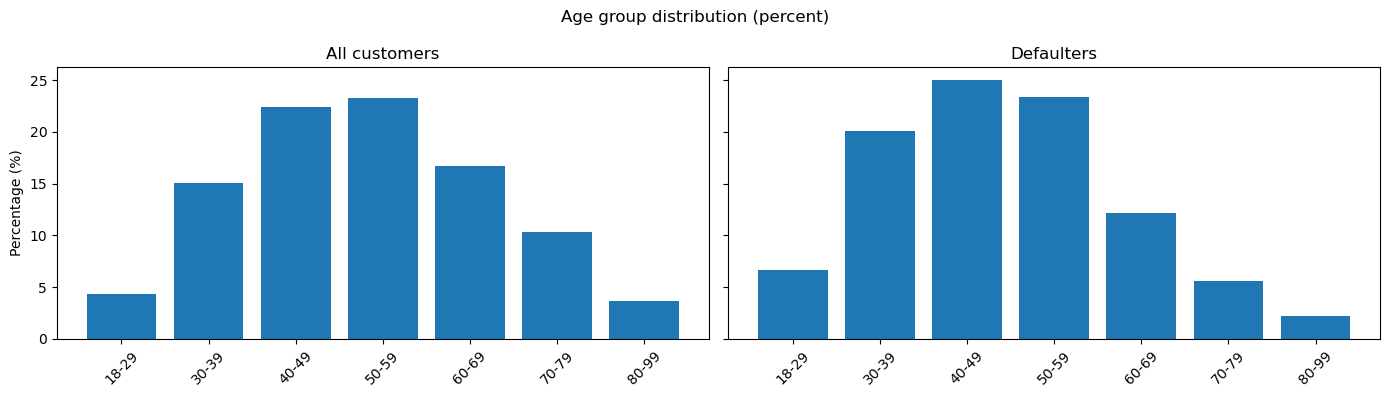

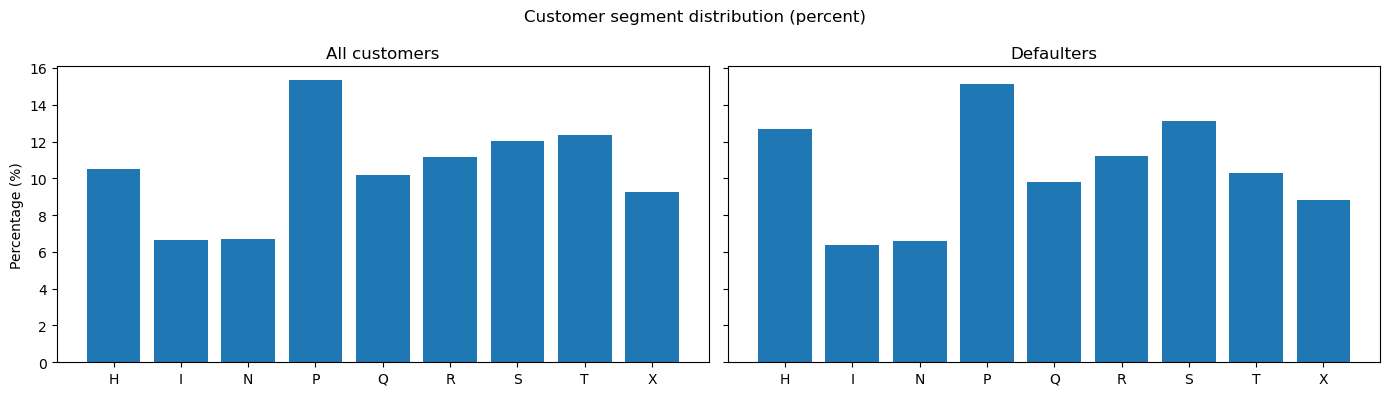

In [7]:
# Age group distribution: all vs defaulters
plot_side_by_side_percent(
    left=cust_base["age_group"],
    right=cust_base.loc[cust_base["target"] == 1, "age_group"],
    title_left="All customers",
    title_right="Defaulters",
    suptitle="Age group distribution (percent)",
    order=sorted(cust_base["age_group"].dropna().unique(), key=str),
)

# Customer segment distribution: all vs defaulters
plot_side_by_side_percent(
    left=cust_base["cust_segment"],
    right=cust_base.loc[cust_base["target"] == 1, "cust_segment"],
    title_left="All customers",
    title_right="Defaulters",
    suptitle="Customer segment distribution (percent)",
    order=sorted(cust_base["cust_segment"].dropna().unique(), key=str),
    rotation=0,
)

**conclusion**  
The age distribution of defaulters differs slightly from the overall population, with customers aged 30–49 appearing somewhat overrepresented among defaults, while older age groups are relatively less represented.

Customer segment distributions show moderate variation between defaulters and the full population, suggesting that certain segments may carry higher default risk.

Overall, demographic and segment features show some signal, but differences are not extreme, indicating that behavioral balance features are likely to add significant predictive value.

### Numnber of products distribution 

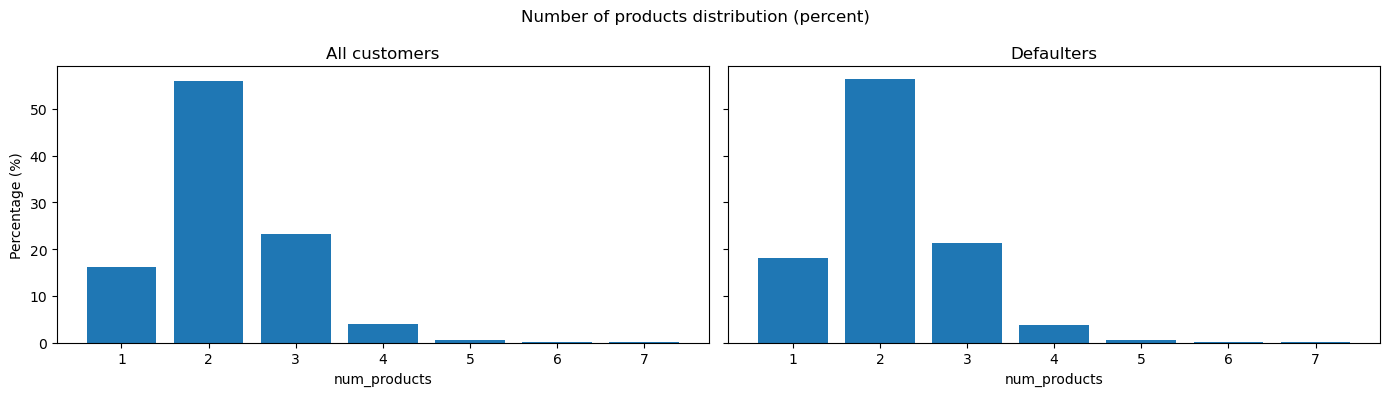

In [8]:
# For discrete numeric, I will show percent distribution via value_counts.
all_np = cust_base["num_products"].value_counts(normalize=True).sort_index() * 100
def_np = cust_base.loc[cust_base["target"] == 1, "num_products"].value_counts(normalize=True).sort_index() * 100

cats = sorted(set(all_np.index).union(set(def_np.index)))

left_vals = [float(all_np.get(c, 0.0)) for c in cats]
right_vals = [float(def_np.get(c, 0.0)) for c in cats]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

axes[0].bar([str(c) for c in cats], left_vals)
axes[0].set_title("All customers")
axes[0].set_ylabel("Percentage (%)")
axes[0].set_xlabel("num_products")

axes[1].bar([str(c) for c in cats], right_vals)
axes[1].set_title("Defaulters")
axes[1].set_xlabel("num_products")

fig.suptitle("Number of products distribution (percent)")
plt.tight_layout()
plt.show()

**Conclusion**

The distribution of the number of products is very similar between the full customer base and defaulters. Customers with two products represent the majority in both groups. There are only minor differences for customers with one or three products.

Overall, the number of products alone does not appear to strongly differentiate defaulters from non-defaulters, suggesting that more dynamic behavioral features (such as balance patterns) are likely to provide stronger predictive power.

### Default rate by group (age_group / segment / num_products)

,age_group,n_customers,default_rate
0,18-29,219,0.305936
1,30-39,752,0.267287
2,40-49,1122,0.222816
3,50-59,1162,0.201377
4,60-69,837,0.145759
5,70-79,516,0.108527
6,80-99,184,0.119565


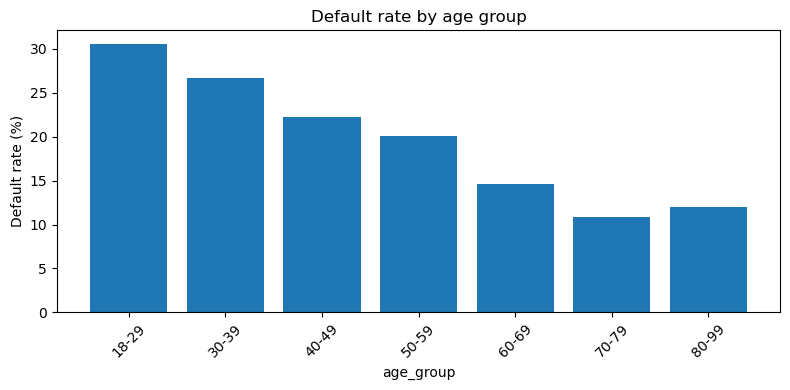

,cust_segment,n_customers,default_rate
0,H,526,0.241445
1,I,333,0.192192
2,N,334,0.197605
3,P,766,0.197128
4,Q,508,0.192913
5,R,558,0.200717
6,S,601,0.217970
7,T,618,0.166667
8,X,462,0.190476


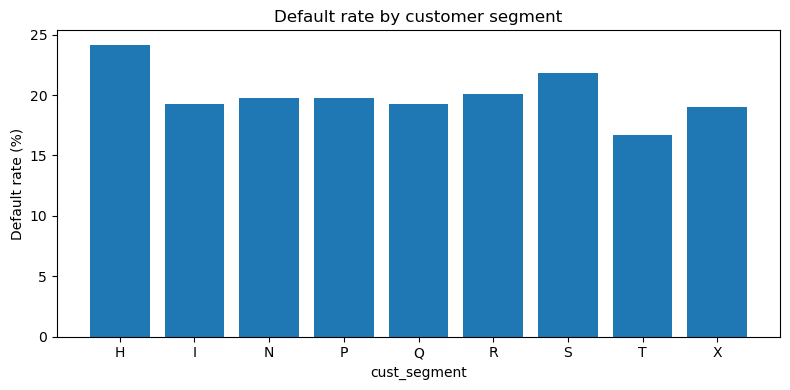

,num_products,n_customers,default_rate
0,1,810,0.222222
1,2,2796,0.201359
2,3,1165,0.182833
3,4,202,0.183168
4,5,25,0.200000
5,6,1,1.000000
6,7,1,1.000000


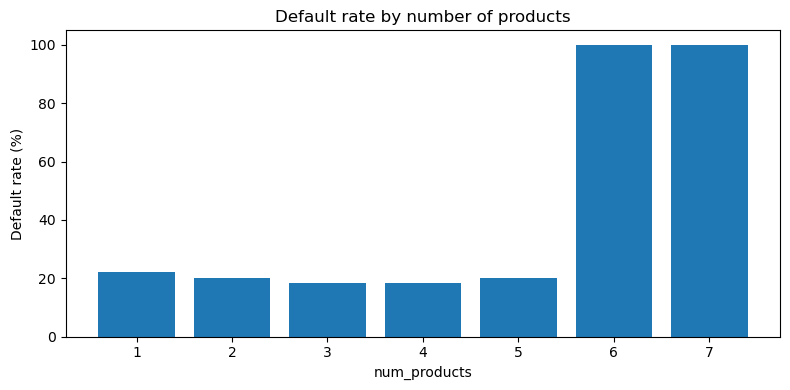

In [9]:
age_rates = default_rate_by_group(cust_base, "age_group", "target")
seg_rates = default_rate_by_group(cust_base, "cust_segment", "target")
np_rates = default_rate_by_group(cust_base, "num_products", "target")

display(age_rates)
plot_default_rate_bar(age_rates, "age_group", title="Default rate by age group")

display(seg_rates)
plot_default_rate_bar(seg_rates, "cust_segment", title="Default rate by customer segment", rotation=0)

display(np_rates)
plot_default_rate_bar(np_rates, "num_products", title="Default rate by number of products", rotation=0)


**conclusion**

Default rates vary meaningfully across age groups, with younger customers (18–39) exhibiting substantially higher default risk compared to older customers. Default risk decreases steadily with age, suggesting age is a strong differentiating factor.

Customer segments show moderate variation in default rates. Segment H and S appear relatively higher risk, while segment T shows comparatively lower default rates. However, differences across segments are less pronounced than across age groups.

For number of products, default rates are fairly similar for customers with 1–5 products. The 100% default rate observed for 6 and 7 products is driven by extremely small sample sizes (n=1) and should not be interpreted as meaningful. Overall, portfolio size alone does not strongly differentiate default risk.

These results suggest that age provides clearer signal than customer segment or number of products, while behavioral financial features are likely to add stronger predictive power.

### EOD balances: quick sanity + business-relevant hint

In [10]:
# Minimal parsing for quick exploration
tmp = case_eod_balances.copy()
tmp["ymd"] = pd.to_datetime(tmp["ymd"], errors="coerce")
tmp = tmp.dropna(subset=["ymd", "prod_id", "bal_eod_eur"])

print("EOD date range:", tmp["ymd"].min(), "to", tmp["ymd"].max())
print("Unique prod_id:", tmp["prod_id"].nunique())
print("Rows:", len(tmp))

# How common are negative balances at the daily product level?
neg_ratio_overall = (tmp["bal_eod_eur"] < 0).mean()
print("Share of daily records with balance < 0:", neg_ratio_overall)


EOD date range: 2013-01-01 00:00:00 to 2016-01-01 00:00:00
Unique prod_id: 7353
Rows: 8042913
Share of daily records with balance < 0: 0.15336769153166271


**conclusion**

The EOD balance dataset spans the full historical period from 2013 to the start of 2016 and contains over 8 million daily records across more than 7,000 products.

Approximately 15% of daily balance observations are negative, indicating that overdraft or liquidity stress situations are relatively common. This supports the hypothesis that negative balance behavior may serve as a meaningful early warning signal for default risk and warrants further customer-level feature engineering.

### Basic customer-level “days below 0” (simple baseline feature)

In [11]:
# Simple baseline feature: days below 0 per product, then aggregate to customer.
tmp["is_neg"] = (tmp["bal_eod_eur"] < 0).astype(int)

prod_neg_days = tmp.groupby("prod_id")["is_neg"].sum().reset_index(name="neg_days_prod")
prod_total_days = tmp.groupby("prod_id")["is_neg"].size().reset_index(name="n_days_prod")

prod_neg = prod_neg_days.merge(prod_total_days, on="prod_id", how="inner")
prod_neg["neg_ratio_prod"] = prod_neg["neg_days_prod"] / prod_neg["n_days_prod"]

# Map products to customers
cust_neg = case_cust_prod_mapping.merge(prod_neg, on="prod_id", how="left")

# Aggregate to customer (simple: sum negative days, mean ratio)
cust_neg_agg = (
    cust_neg.groupby("cust_id")[["neg_days_prod", "n_days_prod", "neg_ratio_prod"]]
    .agg(
        neg_days_sum=("neg_days_prod", "sum"),
        days_sum=("n_days_prod", "sum"),
        neg_ratio_mean=("neg_ratio_prod", "mean"),
    )
    .reset_index()
)

# Merge into customer base
cust_base_v1 = cust_base.merge(cust_neg_agg, on="cust_id", how="left")

display(cust_base_v1[["target", "neg_days_sum", "neg_ratio_mean"]].describe())


,target,neg_days_sum,neg_ratio_mean
count,5000.00000,5000.00000,4997.000000
mean,0.20000,247.32060,0.155735
std,0.40004,400.87328,0.247579
min,0.00000,0.00000,0.000000
25%,0.00000,0.00000,0.000000
50%,0.00000,35.00000,0.023114
75%,0.00000,340.25000,0.212591
max,1.00000,2930.00000,1.000000


**conclusion**

The customer-level aggregation shows substantial variation in negative balance behavior. While the median customer has relatively few days below zero, the distribution is highly skewed, with some customers experiencing prolonged periods of negative balances.

The average negative balance ratio (~15%) aligns with the earlier overall daily estimate, confirming internal consistency. The wide spread and presence of extreme values suggest that liquidity stress differs meaningfully across customers, making these features strong candidates for predictive modeling.

### Compare baseline negative-balance feature for defaulters vs non-defaulters

neg_days_sum        neg_ratio_mean          
               mean median           mean    median
target                                             
0         167.96025   15.0       0.101454  0.010036
1         564.76200  505.5       0.372697  0.322993

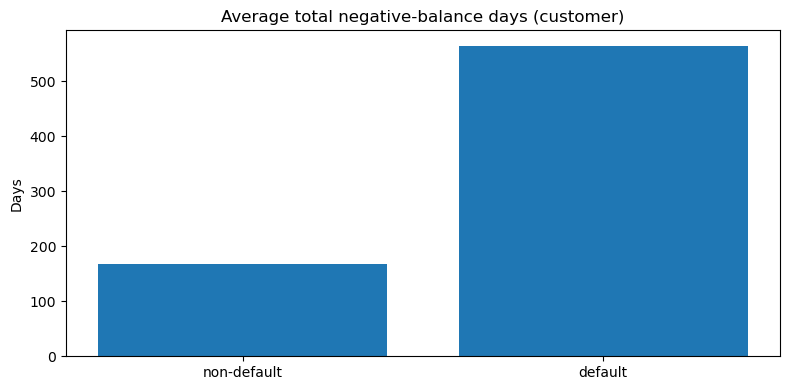

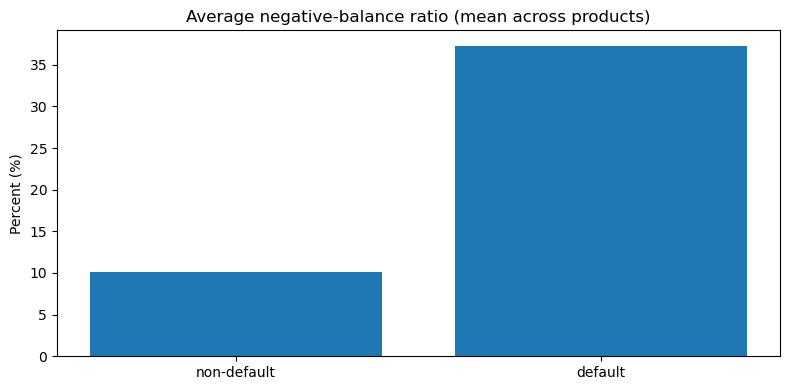

In [12]:
summary = (
    cust_base_v1.groupby("target")[["neg_days_sum", "neg_ratio_mean"]]
    .agg(["mean", "median"])
)
display(summary)

means = cust_base_v1.groupby("target")[["neg_days_sum", "neg_ratio_mean"]].mean()

plt.figure(figsize=(8,4))
plt.bar(["non-default", "default"], means["neg_days_sum"].tolist())
plt.title("Average total negative-balance days (customer)")
plt.ylabel("Days")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,4))
plt.bar(["non-default", "default"], (means["neg_ratio_mean"] * 100).tolist())
plt.title("Average negative-balance ratio (mean across products)")
plt.ylabel("Percent (%)")
plt.tight_layout()
plt.show()


**conclusion**  

Defaulters exhibit substantially higher liquidity stress compared to non-defaulters. On average, defaulters experience more than three times as many negative-balance days, and their negative-balance ratio is also significantly higher (around 37% vs. 10%).

The difference is large and consistent across both mean and median values, indicating that negative balance behavior is strongly associated with default risk. This simple baseline feature already shows strong discriminatory power and supports further development of balance-based risk indicators.

## Summary of exploration

- The target is defined at customer level and can be merged directly with customer attributes.
- Differences in default rates by customer groups (age group, segment, number of products) provide a first segmentation view.
- End-of-day balances include negative values. A simple baseline feature (days with balance < €0) can already be compared between defaulters and non-defaulters.
- Next step: build richer balance-based features (volatility, trends, recent behavior) and train predictive models.
